# Week 3 – Feature selection and feature importance (Jason ZOH)

Research question of the project: *which features matter the most?* We apply the three families of lab 4, always **inside the pipeline** (fitted on the train set, compared on the validation set):

| Family | Principle | Method used here |
|---|---|---|
| Filter | scores each feature alone, without a model | `SelectKBest(mutual_info_classif)`: mutual information between the feature and `success` |
| Embedded | the selection is part of the training | `SelectFromModel` with an L1 logistic regression: the L1 penalty sets coefficients to 0 |
| Wrapper | searches for a subset guided by a model | `RFE`: removes the weakest features of a logistic regression, 10 at a time |

For each method, the selected features are then given to the **baseline logistic regression of notebook 04**, so that the only difference with the baseline is the selection. We work at **T = 0** (information known at release) and **T = 30** (with the first month of reviews).

Then, **permutation importance** on the validation set says which features a strong model (gradient boosting) really uses.

The test set is not used.

In [1]:
import sys
sys.path.append("..")
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif, SelectFromModel, RFE
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from config import *

FIG_DIR = ROOT / "report" / "figures"
target = pd.read_parquet(PROC_DIR / "target.parquet")
static = pd.read_parquet(PROC_DIR / "features_static.parquet")

## 1. Data and pipeline (same as notebooks 04 and 05)

In [2]:
NUM_COLS = ["log_price", "required_age", "n_languages", "desc_length", "n_reviews", "pos_ratio"]
CAT_COLS = ["release_month", "release_weekday"]
T_SEL = [0, 30]

def make_dataset(T):
    df = target[["app_id", "split", "success"]].merge(static, on="app_id")
    if T > 0:
        df = df.merge(pd.read_parquet(PROC_DIR / f"features_T{T}.parquet"), on="app_id")
        df["n_reviews"] = np.log1p(df["n_reviews"])
    df["desc_length"] = np.log1p(df["desc_length"])
    return df

def make_preprocess(X):
    num = [c for c in NUM_COLS if c in X.columns]
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        (OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        remainder="passthrough")

def baseline_lr():
    return LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)

DATA = {}
for T in T_SEL:
    df = make_dataset(T)
    train, val = df[df["split"] == "train"], df[df["split"] == "val"]   # the test set is not used
    drop = ["app_id", "split", "success"]
    DATA[T] = dict(Xtr=train.drop(columns=drop).astype(float), ytr=train["success"],
                   Xva=val.drop(columns=drop).astype(float), yva=val["success"])

ROWS = []

def run(family, T, param, selector):
    # preprocessing -> selection -> baseline logistic regression, fitted on the train set only
    d = DATA[T]
    model = make_pipeline(make_preprocess(d["Xtr"]), selector, baseline_lr()).fit(d["Xtr"], d["ytr"])
    pr_auc = average_precision_score(d["yva"], model.predict_proba(d["Xva"])[:, 1])
    n_kept = model[1].get_support().sum()
    ROWS.append(dict(family=family, T=T, param=param, n_features=n_kept, pr_auc=pr_auc))
    return model

print({T: DATA[T]["Xtr"].shape for T in T_SEL})

{0: (7007, 216), 30: (7007, 219)}


## 2. Filter: mutual information

`mutual_info_classif` measures how much knowing a feature reduces the uncertainty on `success` (0 = independent). It catches non-linear links, unlike a correlation. We keep the `k` best features, with `k` ∈ {10, 20, 50, 100, all}. `k = "all"` keeps every feature: it is the baseline of notebook 04.

In [3]:
mi = partial(mutual_info_classif, random_state=SEED)  # mutual information is estimated with random neighbours

for T in T_SEL:
    for k in [10, 20, 50, 100, "all"]:
        run("filter (mutual information)", T, k, SelectKBest(mi, k=k))
pd.DataFrame(ROWS).round(3)

,family,T,param,n_features,pr_auc
0,filter (mutual information),0,10,10,0.390
1,filter (mutual information),0,20,20,0.393
2,filter (mutual information),0,50,50,0.405
3,filter (mutual information),0,100,100,0.368
4,filter (mutual information),0,all,233,0.407
5,filter (mutual information),30,10,10,0.839
6,filter (mutual information),30,20,20,0.844
7,filter (mutual information),30,50,50,0.844
8,filter (mutual information),30,100,100,0.836
9,filter (mutual information),30,all,236,0.810


## 3. Embedded: L1 logistic regression

The L1 penalty (Lasso) sets the coefficients of the least useful features exactly to 0 (lab 4, part C: soft-thresholding). `SelectFromModel` keeps the features with a non-zero coefficient. A smaller `C` means a stronger penalty, so fewer features.

In [4]:
for T in T_SEL:
    for c in [0.01, 0.03, 0.1, 0.3, 1]:
        lasso = LogisticRegression(solver="saga", l1_ratio=1, C=c, max_iter=3000, random_state=SEED)
        run("embedded (L1)", T, c, SelectFromModel(lasso))
pd.DataFrame(ROWS).query("family == 'embedded (L1)'").round(3)

,family,T,param,n_features,pr_auc
10,embedded (L1),0,0.01,7,0.375
11,embedded (L1),0,0.03,24,0.405
12,embedded (L1),0,0.1,67,0.466
13,embedded (L1),0,0.3,131,0.425
14,embedded (L1),0,1,202,0.412
15,embedded (L1),30,0.01,2,0.837
16,embedded (L1),30,0.03,8,0.842
17,embedded (L1),30,0.1,33,0.852
18,embedded (L1),30,0.3,94,0.830
19,embedded (L1),30,1,171,0.816


## 4. Wrapper: recursive feature elimination (RFE)

`RFE` trains a logistic regression, removes the 10 features with the smallest coefficients (in absolute value), and starts again until `n_features_to_select` remain. Slower than the filter, because it trains one model per step, but it takes the other features into account.

In [5]:
for T in T_SEL:
    for k in [10, 20, 50, 100]:
        rfe = RFE(LogisticRegression(max_iter=1000, random_state=SEED), n_features_to_select=k, step=10)
        run("wrapper (RFE)", T, k, rfe)
pd.DataFrame(ROWS).query("family == 'wrapper (RFE)'").round(3)

,family,T,param,n_features,pr_auc
20,wrapper (RFE),0,10,10,0.377
21,wrapper (RFE),0,20,20,0.386
22,wrapper (RFE),0,50,50,0.430
23,wrapper (RFE),0,100,100,0.434
24,wrapper (RFE),30,10,10,0.841
25,wrapper (RFE),30,20,20,0.838
26,wrapper (RFE),30,50,50,0.832
27,wrapper (RFE),30,100,100,0.827


## 5. Comparison of the three families

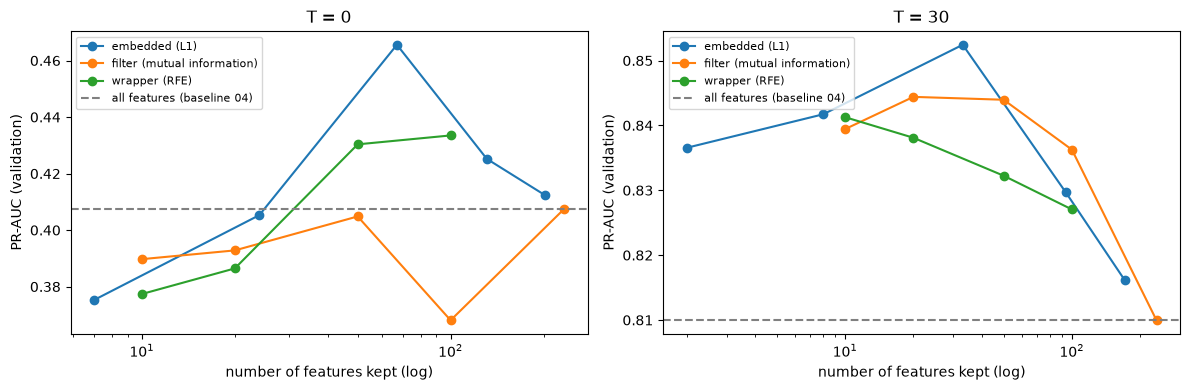

In [6]:
sel = pd.DataFrame(ROWS)
sel.to_csv(ROOT / "report" / "results_feature_selection.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, T in zip(axes, T_SEL):
    part = sel[sel["T"] == T]
    for family, g in part.groupby("family"):
        g = g.sort_values("n_features")
        ax.plot(g["n_features"], g["pr_auc"], marker="o", label=family)
    all_features = part.loc[part["param"] == "all", "pr_auc"].iloc[0]
    ax.axhline(all_features, color="gray", ls="--", label="all features (baseline 04)")
    ax.set(xscale="log", xlabel="number of features kept (log)", ylabel="PR-AUC (validation)", title=f"T = {T}")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_selection.png", dpi=150); plt.show()

**What to look for:** how many features can be removed without losing PR-AUC (point where each curve reaches the dashed line), which family reaches it with the fewest features, and whether selection matters more at T = 0 (about 240 weak features) than at T = 30 (a few strong review features).

**Reading (Jason):** at T = 30, every family beats the baseline with all 236 features (0.810): about 10 features are enough to reach 0.84 with each of them, and the best is the L1 selection with 33 features (0.852). The baseline logistic regression (C = 1, no selection) overfits its many 0/1 features; the grid search of notebook 05 also chose an L1 penalty. At T = 0 the store features are weak and the curves are noisy: only L1 with 67 features (0.466) and RFE with 50 to 100 features (0.43) beat the baseline (0.407), while the mutual information filter never does, probably because it scores each feature alone. These differences at T = 0 are small compared with the bootstrap interval of the baseline ([0.34, 0.47]). The embedded L1 selection is the best family at both T.

Selecting the features **inside** the pipeline matters: selecting them once on all the data before splitting would let the validation games influence the choice and overestimate the score (lab 4, Q5).

### Features kept by the L1 selection

For the value of `C` with the best validation PR-AUC, the features that keep a non-zero coefficient, sorted by the absolute value of their coefficient in the L1 model.

In [7]:
for T in T_SEL:
    d = DATA[T]
    best_c = sel.query("family == 'embedded (L1)' and T == @T").sort_values("pr_auc").iloc[-1]["param"]
    lasso = LogisticRegression(solver="saga", l1_ratio=1, C=best_c, max_iter=3000, random_state=SEED)
    model = make_pipeline(make_preprocess(d["Xtr"]), SelectFromModel(lasso), baseline_lr()).fit(d["Xtr"], d["ytr"])
    names = model[0].get_feature_names_out()
    coefs = pd.Series(model[1].estimator_.coef_[0], index=names)
    kept = coefs[coefs != 0].sort_values(key=abs, ascending=False)
    print(f"T = {T}: C = {best_c}, {len(kept)} features kept out of {len(names)}. The 15 strongest:")
    print(kept.head(15).round(2).to_string(), "\n")

T = 0: C = 0.1, 67 features kept out of 233. The 15 strongest:
remainder__is_free                   1.42
remainder__tag_Singleplayer          0.75
remainder__cat_Steam Cloud           0.70
remainder__tag_Hentai                0.67
remainder__tag_Great Soundtrack      0.66
remainder__cat_Steam Workshop        0.60
remainder__tag_Visual Novel          0.54
remainder__tag_Anime                 0.54
remainder__tag_Memes                 0.46
remainder__cat_Steam Achievements    0.45
remainder__tag_Multiplayer           0.41
remainder__in_fronkon                0.40
pipeline__log_price                  0.40
remainder__tag_Pixel Graphics        0.37
remainder__mac                       0.35 



T = 30: C = 0.1, 33 features kept out of 236. The 15 strongest:
pipeline__n_reviews                     2.93
pipeline__pos_ratio                     2.33
remainder__tag_Open World              -0.65
remainder__tag_2D                       0.36
remainder__tag_Horror                   0.32
remainder__genre_Indie                  0.30
remainder__cat_Steam Cloud              0.28
remainder__tag_Puzzle                   0.28
remainder__tag_Massively Multiplayer   -0.25
remainder__tag_Adventure               -0.23
remainder__tag_Singleplayer             0.23
remainder__tag_Visual Novel             0.21
remainder__cat_PvP                     -0.18
onehotencoder__release_month_3.0       -0.17
pipeline__required_age                 -0.15 



## 6. Permutation importance (gradient boosting, validation set)

For each feature, we shuffle its values among the validation games and measure how much the PR-AUC drops: a large drop means that the model relies on this feature. Unlike coefficients, this works for any model, and it is measured on the validation set, so it reflects what generalises.

The model is a gradient boosting with default parameters (fast, and close to the best model of notebook 05). The features are the columns **before** preprocessing (e.g. one `release_month` column, not 12 one-hot columns).

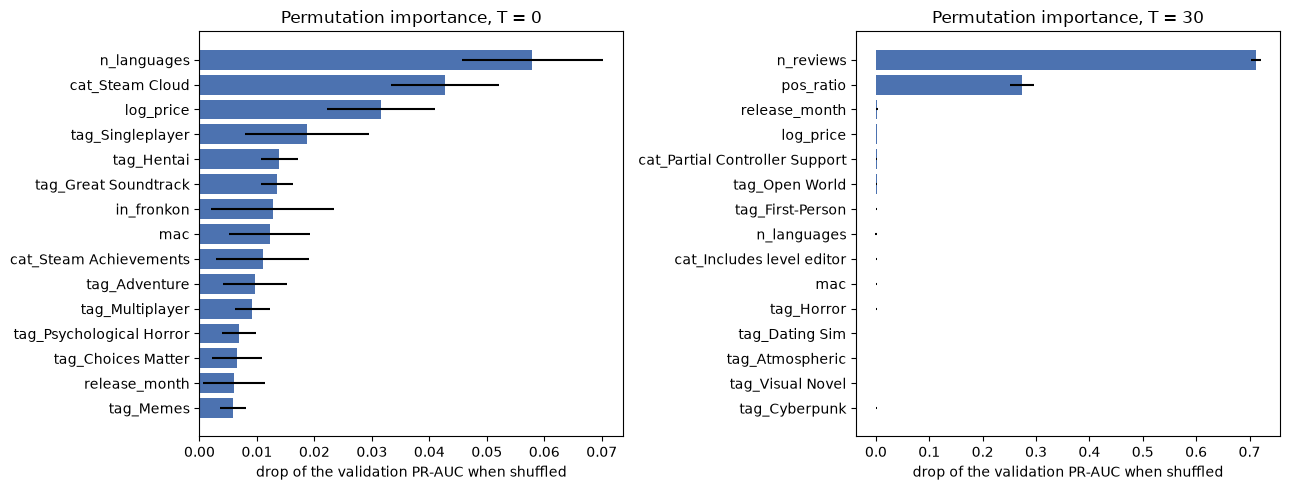

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, T in zip(axes, T_SEL):
    d = DATA[T]
    gb = make_pipeline(make_preprocess(d["Xtr"]), HistGradientBoostingClassifier(random_state=SEED))
    gb.fit(d["Xtr"], d["ytr"])
    imp = permutation_importance(gb, d["Xva"], d["yva"], scoring="average_precision",
                                 n_repeats=10, random_state=SEED, n_jobs=-1)
    imp = pd.DataFrame({"mean": imp.importances_mean, "std": imp.importances_std}, index=d["Xva"].columns)
    top = imp.sort_values("mean").tail(15)
    ax.barh(top.index, top["mean"], xerr=top["std"], color="#4C72B0")
    ax.set(xlabel="drop of the validation PR-AUC when shuffled", title=f"Permutation importance, T = {T}")
plt.tight_layout(); plt.savefig(FIG_DIR / "permutation_importance.png", dpi=150); plt.show()

**What to look for:** at T = 0, which store information matters (genres, tags, languages, price?); at T = 30, whether the early reviews (`n_reviews`, `pos_ratio`) dominate everything else. A feature with an importance close to 0 (error bar crossing 0) is not used by the model.

**Reading (Jason):** at T = 30, the model relies almost only on the early reviews: shuffling `n_reviews` makes the PR-AUC drop by about 0.71 and `pos_ratio` by about 0.27; every other feature costs less than 0.01. At T = 0, the most used features are the number of languages (≈ 0.06), Steam Cloud (≈ 0.04) and the price (≈ 0.03), then a few tags (Singleplayer, Hentai, Great Soundtrack); the drops are small and the error bars wide. `is_free` has the largest L1 coefficient but is not in the top 15 here: it carries almost the same information as `log_price` (price 0), and when two features carry the same information, shuffling one of them costs little because the model still has the other.

**Answer to the research question:** at release, what matters most is the reach of the game (number of languages, platforms, Steam Cloud and Workshop), its price (free or not) and a few niche tags, but together they only give a PR-AUC of about 0.4 to 0.5. After one month, the number of reviews and their share of positive reviews carry almost all the information: the rest of the store page adds almost nothing.